# Mixtral of Experts (Mixtral 8x7B)

**Paper:** [arXiv:2401.04088](https://arxiv.org/abs/2401.04088)
**Authors:** Albert Q. Jiang, Alexandre Sablayrolles, Antoine Roux, Arthur Mensch, et al. (Mistral AI, 2024)

This notebook implements a simplified Sparse Mixture-of-Experts (SMoE) language model from scratch in PyTorch,
demonstrating the core top-2 routing mechanism from Mixtral 8x7B.
A router network selects 2 of 8 expert feedforward blocks per token and combines their outputs additively.

**Simplifications vs the paper** (same list as README and CODE_ARCHITECTURE):
- Tiny Shakespeare character-level dataset instead of multilingual pretraining data
- 4 layers, 4 heads, 128 dim, 8 experts (top-2) — about 6.5M total / 1.8M active params (vs 46.7B total / 12.9B active)
- 15 epochs with AdamW (lr=1e-3) instead of full-scale pretraining
- No load-balancing loss (the paper does not use one either; Mixtral relies on architecture, not auxiliary losses)
- Expert routing visualization on sample text (as in the paper's Section 5 routing analysis)


## 1. Setup & Imports

In [1]:
import contextlib
import io
import math
import random
import time
import urllib.request

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
EPOCHS = 15
BATCH_SIZE = 32
LR = 1e-3
N_LAYERS = 4
D_MODEL = 128
N_HEADS = 4
N_KV_HEADS = 2
D_HEAD = 32
N_EXPERTS = 8
TOP_K = 2
CONTEXT_LEN = 128
STEPS_PER_EPOCH = 80
FFN_DIM = 512

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')


Device: cuda


## 2. Data

Tiny Shakespeare (~1 MB, 65 unique characters). Downloaded quietly to /tmp.
Character-level tokenization, 90/10 train/val split.


In [2]:
with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
    url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
    urllib.request.urlretrieve(url, '/tmp/tinyshakespeare.txt')

with open('/tmp/tinyshakespeare.txt', 'r') as f:
    text = f.read()

chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: ''.join([itos[i] for i in l])

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f'Vocab size: {vocab_size}')
print(f'Train tokens: {len(train_data)}, Val tokens: {len(val_data)}')
print(f'Sample: {decode(train_data[:100].tolist())!r}')


Vocab size: 65
Train tokens: 1003854, Val tokens: 111540
Sample: 'First Citizen:\nBefore we proceed any further, hear me speak.\n\nAll:\nSpeak, speak.\n\nFirst Citizen:\nYou'


## 3. Model

We implement two models for comparison:
- **Dense Transformer**: standard FFN sub-block (same architecture otherwise)
- **MoE Transformer**: FFN sub-block replaced by a Sparse Mixture-of-Experts layer with 8 experts, top-2 routing

Both share: GQA attention (4 query heads, 2 KV heads), SwiGLU FFN, RMSNorm, pre-norm residual.

### Sparse MoE Layer (Section 2.1 of the paper)

The router is a linear layer `W_g` that maps the hidden state to `n_experts` logits.
Top-K=2 experts are selected per token. The gating weights are the softmax of the top-2 logits.
The output is the weighted sum of the two selected expert outputs:

```
y = sum_i softmax(Top2(x @ W_g))_i * SwiGLU_i(x)
```


In [3]:
class GroupedQueryAttention(nn.Module):
    """GQA attention as in Mixtral/Mistral 7B."""
    def __init__(self, d_model, n_heads, n_kv_heads, d_head):
        super().__init__()
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads
        self.d_head = d_head
        self.wq = nn.Linear(d_model, n_heads * d_head, bias=False)
        self.wk = nn.Linear(d_model, n_kv_heads * d_head, bias=False)
        self.wv = nn.Linear(d_model, n_kv_heads * d_head, bias=False)
        self.wo = nn.Linear(n_heads * d_head, d_model, bias=False)
    
    def forward(self, x):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_heads, self.d_head).transpose(1, 2)
        k = self.wk(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)
        v = self.wv(x).view(B, T, self.n_kv_heads, self.d_head).transpose(1, 2)
        # Repeat KV heads to match query heads
        rep = self.n_heads // self.n_kv_heads
        k = k.repeat_interleave(rep, dim=1)
        v = v.repeat_interleave(rep, dim=1)
        # Causal attention via SDPA
        out = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        out = out.transpose(1, 2).contiguous().view(B, T, self.n_heads * self.d_head)
        return self.wo(out)


In [4]:
class SwiGLUExpert(nn.Module):
    """A single SwiGLU feedforward block (one 'expert' in MoE, or the dense FFN)."""
    def __init__(self, d_model, ffn_dim):
        super().__init__()
        self.w1 = nn.Linear(d_model, ffn_dim, bias=False)  # gate
        self.w2 = nn.Linear(ffn_dim, d_model, bias=False)  # down
        self.w3 = nn.Linear(d_model, ffn_dim, bias=False)  # up
    
    def forward(self, x):
        return self.w2(F.silu(self.w1(x)) * self.w3(x))


In [5]:
class MoELayer(nn.Module):
    """Sparse Mixture-of-Experts layer with top-K routing (Mixtral Section 2.1).
    
    Router: G(x) = softmax(TopK(x @ W_g))
    Output: sum_i G(x)_i * Expert_i(x)  over the top-K experts
    """
    def __init__(self, d_model, ffn_dim, n_experts, top_k):
        super().__init__()
        self.n_experts = n_experts
        self.top_k = top_k
        self.experts = nn.ModuleList([
            SwiGLUExpert(d_model, ffn_dim) for _ in range(n_experts)
        ])
        self.router = nn.Linear(d_model, n_experts, bias=False)
    
    def forward(self, x):
        """x: (B, T, d_model) -> (B, T, d_model)
        Also returns routing weights and selected expert indices for analysis.
        """
        B, T, C = x.shape
        x_flat = x.view(B * T, C)
        # Router logits: (B*T, n_experts)
        logits = self.router(x_flat)
        # Top-K selection
        topk_logits, topk_indices = torch.topk(logits, self.top_k, dim=-1)
        # Softmax over only the top-K logits (others get -inf, effectively 0)
        topk_weights = F.softmax(topk_logits, dim=-1)
        # Compute expert outputs and combine
        output = torch.zeros_like(x_flat)
        for i in range(self.top_k):
            expert_idx = topk_indices[:, i]  # (B*T,)
            weight = topk_weights[:, i:i+1]  # (B*T, 1)
            for e in range(self.n_experts):
                mask = (expert_idx == e)
                if mask.any():
                    expert_out = self.experts[e](x_flat[mask])
                    output[mask] += weight[mask] * expert_out
        
        return output.view(B, T, C), topk_weights.view(B, T, self.top_k), topk_indices.view(B, T, self.top_k)


In [6]:
class DenseFFN(nn.Module):
    """Standard dense FFN using a single SwiGLU block."""
    def __init__(self, d_model, ffn_dim):
        super().__init__()
        self.ffn = SwiGLUExpert(d_model, ffn_dim)
    
    def forward(self, x):
        return self.ffn(x)


In [7]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads, d_head, ffn_dim, use_moe, n_experts, top_k):
        super().__init__()
        self.attn = GroupedQueryAttention(d_model, n_heads, n_kv_heads, d_head)
        self.norm1 = nn.RMSNorm(d_model)
        if use_moe:
            self.ffn = MoELayer(d_model, ffn_dim, n_experts, top_k)
        else:
            self.ffn = DenseFFN(d_model, ffn_dim)
        self.norm2 = nn.RMSNorm(d_model)
        self.use_moe = use_moe
    
    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        if self.use_moe:
            ffn_out, routing_weights, expert_indices = self.ffn(self.norm2(x))
            x = x + ffn_out
            return x, routing_weights, expert_indices
        else:
            x = x + self.ffn(self.norm2(x))
            return x, None, None


In [8]:
class LanguageModel(nn.Module):
    def __init__(self, vocab_size, d_model, n_heads, n_kv_heads, d_head, n_layers, ffn_dim, use_moe, n_experts, top_k):
        super().__init__()
        self.token_emb = nn.Embedding(vocab_size, d_model)
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, n_kv_heads, d_head, ffn_dim, use_moe, n_experts, top_k)
            for _ in range(n_layers)
        ])
        self.norm = nn.RMSNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        # Weight tying
        self.head.weight = self.token_emb.weight
        self.use_moe = use_moe
    
    def forward(self, idx):
        B, T = idx.shape
        x = self.token_emb(idx)
        all_routing = []
        all_experts = []
        for block in self.blocks:
            x, rw, ei = block(x)
            if rw is not None:
                all_routing.append(rw)
                all_experts.append(ei)
        x = self.norm(x)
        logits = self.head(x)
        return logits, all_routing, all_experts


In [9]:
model_dense = LanguageModel(vocab_size, D_MODEL, N_HEADS, N_KV_HEADS, D_HEAD, N_LAYERS, FFN_DIM,
                            use_moe=False, n_experts=N_EXPERTS, top_k=TOP_K).to(DEVICE)
model_moe = LanguageModel(vocab_size, D_MODEL, N_HEADS, N_KV_HEADS, D_HEAD, N_LAYERS, FFN_DIM,
                          use_moe=True, n_experts=N_EXPERTS, top_k=TOP_K).to(DEVICE)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

dense_params = count_params(model_dense)
moe_total = count_params(model_moe)
# Active params: attention + embeddings + top-2 experts (instead of all 8)
single_expert_params = sum(p.numel() for p in model_moe.blocks[0].ffn.experts[0].parameters())
moe_active = moe_total - N_LAYERS * N_EXPERTS * single_expert_params + N_LAYERS * TOP_K * single_expert_params

print(f'Dense model:     {dense_params:,} total params')
print(f'MoE model:       {moe_total:,} total params (sparse)')
print(f'MoE active:      {moe_active:,} params per token (top-{TOP_K} of {N_EXPERTS} experts)')
print(f'Single expert:   {single_expert_params:,} params')
print(f'Ratio (total/active): {moe_total / moe_active:.1f}x')


Dense model:     992,512 total params
MoE model:       6,501,632 total params (sparse)
MoE active:      1,783,040 params per token (top-2 of 8 experts)
Single expert:   196,608 params
Ratio (total/active): 3.6x


## 4. Loss Function

Standard cross-entropy loss for next-token prediction.
Both models use `F.cross_entropy(logits.view(-1, vocab_size), targets.view(-1))`.


In [10]:
def get_batch(split):
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([data[i:i+CONTEXT_LEN] for i in ix])
    y = torch.stack([data[i+1:i+CONTEXT_LEN+1] for i in ix])
    return x.to(DEVICE), y.to(DEVICE)


## 5. Training Loop

Both models trained identically: AdamW (lr=1e-3, wd=0.1, betas=(0.9, 0.95)),
gradient clipping at 1.0, 15 epochs x 80 steps per epoch, batch 32.
Validation loss evaluated every 5 epochs on 50 batches.


In [11]:
def train_model(model, name):
    optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=0.1, betas=(0.9, 0.95))
    train_losses = []
    val_losses = []
    
    t0 = time.time()
    for epoch in range(EPOCHS):
        model.train()
        epoch_loss = 0.0
        for step in range(STEPS_PER_EPOCH):
            x, y = get_batch('train')
            logits, _, _ = model(x)
            loss = F.cross_entropy(logits.view(-1, vocab_size), y.view(-1))
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            epoch_loss += loss.item()
        avg_loss = epoch_loss / STEPS_PER_EPOCH
        train_losses.append(avg_loss)
        
        if (epoch + 1) % 5 == 0 or epoch == 0:
            model.eval()
            vloss = 0.0
            with torch.no_grad():
                for _ in range(50):
                    x, y = get_batch('val')
                    logits, _, _ = model(x)
                    vloss += F.cross_entropy(logits.view(-1, vocab_size), y.view(-1)).item()
            vloss /= 50
            val_losses.append(vloss)
            print(f'{name} | Epoch {epoch+1:2d}/{EPOCHS} | train_loss={avg_loss:.4f} | val_loss={vloss:.4f}')
        else:
            val_losses.append(None)
    
    elapsed = time.time() - t0
    # Final validation
    model.eval()
    final_vloss = 0.0
    with torch.no_grad():
        for _ in range(50):
            x, y = get_batch('val')
            logits, _, _ = model(x)
            final_vloss += F.cross_entropy(logits.view(-1, vocab_size), y.view(-1)).item()
    final_vloss /= 50
    final_ppl = math.exp(final_vloss)
    
    print(f'{name} | Final val_loss={final_vloss:.4f} | val_ppl={final_ppl:.2f} | time={elapsed:.1f}s')
    return {'train_losses': train_losses, 'val_losses': val_losses, 'final_vloss': final_vloss, 'final_ppl': final_ppl, 'elapsed': elapsed}


In [12]:
print('=== Training Dense Transformer ===')
hist_dense = train_model(model_dense, 'Dense')
print()
print('=== Training MoE Transformer ===')
hist_moe = train_model(model_moe, 'MoE')


=== Training Dense Transformer ===


Dense | Epoch  1/15 | train_loss=10.5098 | val_loss=2.6320


Dense | Epoch  5/15 | train_loss=2.4395 | val_loss=2.4858


Dense | Epoch 10/15 | train_loss=2.3320 | val_loss=2.4161


Dense | Epoch 15/15 | train_loss=2.2527 | val_loss=2.3586


Dense | Final val_loss=2.3596 | val_ppl=10.59 | time=20.7s

=== Training MoE Transformer ===


MoE | Epoch  1/15 | train_loss=9.1276 | val_loss=2.5617


MoE | Epoch  5/15 | train_loss=2.4301 | val_loss=2.4523


MoE | Epoch 10/15 | train_loss=2.3265 | val_loss=2.4013


MoE | Epoch 15/15 | train_loss=2.2397 | val_loss=2.3401


MoE | Final val_loss=2.3291 | val_ppl=10.27 | time=100.6s


## 6. Training Curves

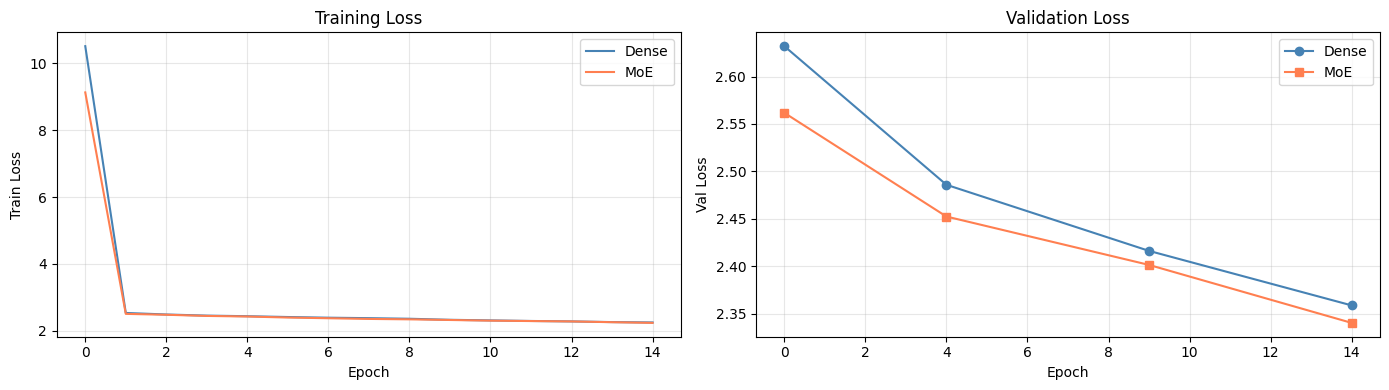

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(hist_dense['train_losses'], label='Dense', color='steelblue')
axes[0].plot(hist_moe['train_losses'], label='MoE', color='coral')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Train Loss')
axes[0].set_title('Training Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Validation loss (non-None entries)
val_epochs_dense = [i for i, v in enumerate(hist_dense['val_losses']) if v is not None]
val_vals_dense = [v for v in hist_dense['val_losses'] if v is not None]
val_epochs_moe = [i for i, v in enumerate(hist_moe['val_losses']) if v is not None]
val_vals_moe = [v for v in hist_moe['val_losses'] if v is not None]

axes[1].plot(val_epochs_dense, val_vals_dense, 'o-', label='Dense', color='steelblue')
axes[1].plot(val_epochs_moe, val_vals_moe, 's-', label='MoE', color='coral')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Val Loss')
axes[1].set_title('Validation Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 7. Final Evaluation

In [14]:
# Uniform baseline: predict each token with probability 1/vocab_size
base_loss = math.log(vocab_size)
base_ppl = vocab_size

print(f'Baseline (uniform):   val_loss={base_loss:.4f} | val_ppl={base_ppl:.2f}')
print(f'Dense Transformer:    val_loss={hist_dense["final_vloss"]:.4f} | val_ppl={hist_dense["final_ppl"]:.2f} | params={dense_params:,}')
print(f'MoE Transformer:      val_loss={hist_moe["final_vloss"]:.4f} | val_ppl={hist_moe["final_ppl"]:.2f} | params={moe_total:,} (total), {moe_active:,} (active)')
print()
improvement = (hist_dense['final_ppl'] - hist_moe['final_ppl']) / hist_dense['final_ppl'] * 100
print(f'MoE vs Dense perplexity: {improvement:+.1f}%')
print(f'Parameter ratio: MoE total / Dense = {moe_total / dense_params:.2f}x')
print(f'Parameter ratio: MoE active / Dense = {moe_active / dense_params:.2f}x')


Baseline (uniform):   val_loss=4.1744 | val_ppl=65.00
Dense Transformer:    val_loss=2.3596 | val_ppl=10.59 | params=992,512
MoE Transformer:      val_loss=2.3291 | val_ppl=10.27 | params=6,501,632 (total), 1,783,040 (active)

MoE vs Dense perplexity: +3.0%
Parameter ratio: MoE total / Dense = 6.55x
Parameter ratio: MoE active / Dense = 1.80x


## 8. Expert Routing Visualization

As in the paper's Section 5 (Routing Analysis), we visualize which expert each token is routed to.
We process a sample text and show the first-choice expert assignment per token across layers.


In [15]:
# Get routing data from the trained MoE model on a sample sequence
sample_text = "To be, or not to be, that is the question:\nWhether tis nobler"
sample_ids = torch.tensor([encode(sample_text)], dtype=torch.long).to(DEVICE)

model_moe.eval()
with torch.no_grad():
    logits, routing_weights, expert_indices = model_moe(sample_ids)

# expert_indices: list of (1, T, top_k) per layer
# routing_weights: list of (1, T, top_k) per layer
T = sample_ids.shape[1]
tokens = list(sample_text)

print(f'Sample text ({T} tokens): {sample_text!r}')
print(f'Number of layers with routing data: {len(expert_indices)}')
print()

# Show first-choice expert for each token at each layer
for layer_idx in range(len(expert_indices)):
    first_choice = expert_indices[layer_idx][0, :, 0].cpu().numpy()  # (T,)
    print(f'Layer {layer_idx:2d} first-choice experts: {first_choice.tolist()}')


Sample text (61 tokens): 'To be, or not to be, that is the question:\nWhether tis nobler'
Number of layers with routing data: 4

Layer  0 first-choice experts: [7, 1, 2, 3, 5, 4, 2, 1, 5, 2, 3, 1, 5, 2, 5, 1, 2, 3, 5, 4, 2, 5, 4, 1, 5, 2, 5, 7, 2, 5, 4, 5, 2, 7, 5, 5, 7, 5, 5, 1, 3, 7, 6, 7, 4, 5, 5, 4, 5, 5, 2, 5, 5, 7, 2, 3, 1, 3, 3, 5, 5]
Layer  1 first-choice experts: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4]
Layer  2 first-choice experts: [4, 4, 4, 4, 4, 7, 4, 4, 4, 4, 4, 4, 7, 4, 4, 4, 4, 4, 4, 7, 4, 4, 4, 4, 7, 4, 4, 4, 4, 7, 7, 4, 4, 4, 4, 4, 4, 7, 4, 7, 7, 7, 4, 4, 7, 4, 7, 7, 4, 7, 4, 7, 4, 7, 4, 7, 4, 7, 7, 4, 7]
Layer  3 first-choice experts: [6, 1, 1, 1, 1, 6, 1, 1, 1, 1, 1, 1, 1, 1, 6, 1, 1, 1, 1, 6, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 6, 1, 1, 1, 1, 1, 1, 1, 1, 6, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


/tmp/ipykernel_24/2670932200.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


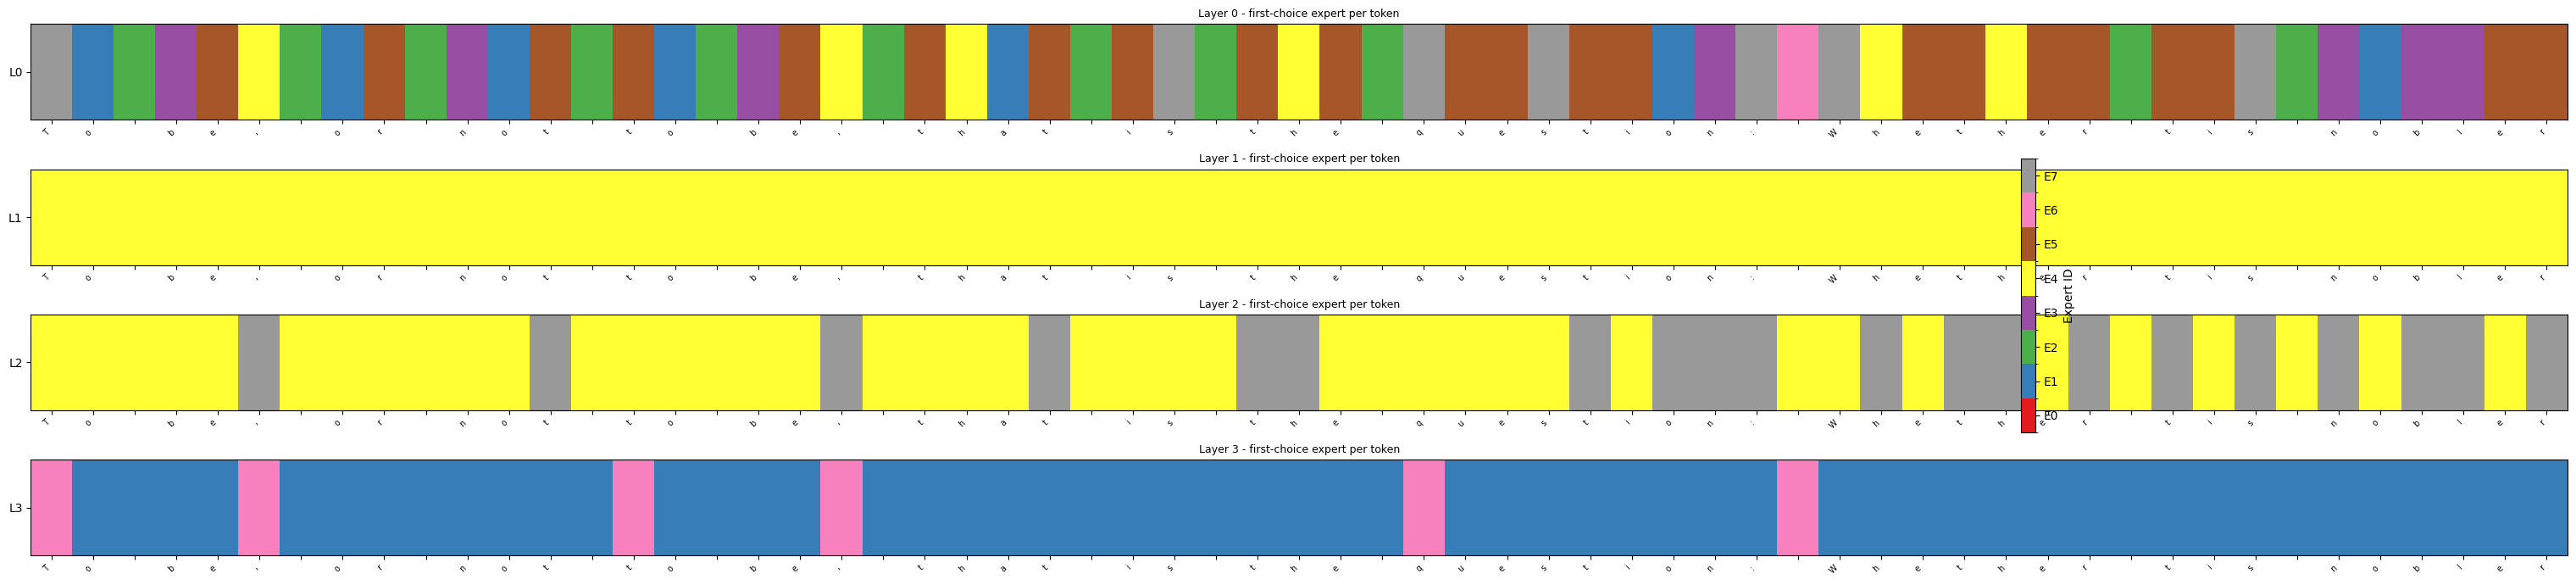

In [16]:
# Visualize expert assignment as a heatmap: layers x tokens
fig, axes = plt.subplots(N_LAYERS, 1, figsize=(max(14, T * 0.5), N_LAYERS * 1.5 + 1))
if N_LAYERS == 1:
    axes = [axes]

# Create a discrete colormap for 8 experts
colors = plt.cm.Set1(np.linspace(0, 1, N_EXPERTS))
cmap = mcolors.ListedColormap(colors)
bounds = np.arange(N_EXPERTS + 1) - 0.5
norm = mcolors.BoundaryNorm(bounds, cmap.N)

for layer_idx in range(N_LAYERS):
    first_choice = expert_indices[layer_idx][0, :, 0].cpu().numpy()  # (T,)
    ax = axes[layer_idx]
    im = ax.imshow(first_choice.reshape(1, -1), cmap=cmap, norm=norm, aspect='auto')
    ax.set_yticks([0])
    ax.set_yticklabels([f'L{layer_idx}'])
    ax.set_xticks(range(T))
    ax.set_xticklabels(tokens, fontsize=7, rotation=45, ha='right')
    ax.set_title(f'Layer {layer_idx} - first-choice expert per token', fontsize=9)

# Colorbar
cbar = fig.colorbar(im, ax=axes, ticks=range(N_EXPERTS), label='Expert ID', shrink=0.6)
cbar.ax.set_yticklabels([f'E{i}' for i in range(N_EXPERTS)])
plt.tight_layout()
plt.show()


## 9. Expert Frequency Analysis

Following the paper's Figure 7, we measure the distribution of expert assignments
on a larger sample of text. The gray dashed line at 1/8 = 12.5% marks uniform sampling.


Layer 0: min=0.0% max=25.1% std=8.00
Layer 1: min=0.0% max=90.3% std=29.46
Layer 2: min=0.0% max=77.5% std=25.65
Layer 3: min=0.0% max=89.5% std=29.29


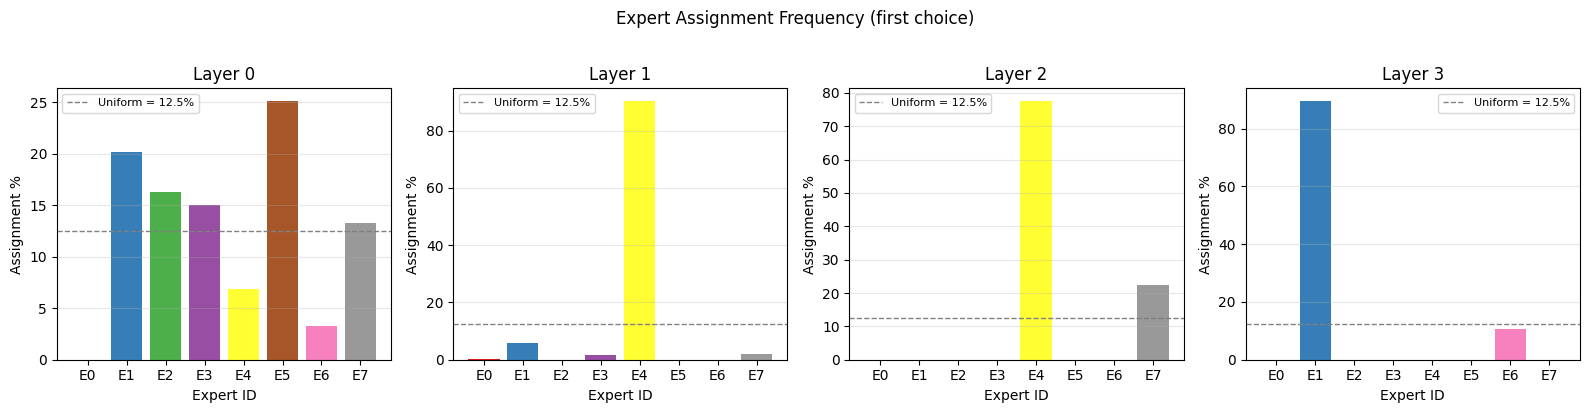

In [17]:
# Process a larger sample to measure expert frequency distribution
large_sample = val_data[:2048].unsqueeze(0).to(DEVICE)

model_moe.eval()
with torch.no_grad():
    _, _, large_expert_indices = model_moe(large_sample)

# Count first-choice expert assignments per layer
fig, axes = plt.subplots(1, N_LAYERS, figsize=(4 * N_LAYERS, 4))
if N_LAYERS == 1:
    axes = [axes]

for layer_idx in range(N_LAYERS):
    first_choice = large_expert_indices[layer_idx][0, :, 0].cpu().numpy()
    counts = np.bincount(first_choice, minlength=N_EXPERTS)
    freqs = counts / counts.sum() * 100
    
    ax = axes[layer_idx]
    bars = ax.bar(range(N_EXPERTS), freqs, color=[colors[i] for i in range(N_EXPERTS)])
    ax.axhline(y=100/N_EXPERTS, color='gray', linestyle='--', linewidth=1, label=f'Uniform = {100/N_EXPERTS:.1f}%')
    ax.set_xlabel('Expert ID')
    ax.set_ylabel('Assignment %')
    ax.set_title(f'Layer {layer_idx}')
    ax.set_xticks(range(N_EXPERTS))
    ax.set_xticklabels([f'E{i}' for i in range(N_EXPERTS)])
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3, axis='y')
    
    print(f'Layer {layer_idx}: min={freqs.min():.1f}% max={freqs.max():.1f}% std={freqs.std():.2f}')

plt.suptitle('Expert Assignment Frequency (first choice)', fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


## 10. Consecutive Token Routing Locality

The paper's Table 5 measures the proportion of consecutive tokens that get the same expert.
We replicate this analysis on our trained model.


In [18]:
# Measure consecutive token routing locality (Table 5 of the paper)
print('Proportion of consecutive tokens with same expert assignment:')
print(f'{"Layer":<8} {"First choice":<15} {"First or second":<18}')
print('-' * 45)

for layer_idx in range(N_LAYERS):
    ei = large_expert_indices[layer_idx][0].cpu().numpy()  # (T, 2)
    T_len = ei.shape[0]
    
    # First choice repetition
    first_repeat = np.mean(ei[:-1, 0] == ei[1:, 0]) * 100
    
    # First or second choice repetition: same expert appears in either pair's top-2
    both_repeat = 0
    for t in range(T_len - 1):
        set_t = set(ei[t, :2])
        set_next = set(ei[t+1, :2])
        if set_t & set_next:  # any overlap
            both_repeat += 1
    both_repeat = both_repeat / (T_len - 1) * 100
    
    print(f'{layer_idx:<8} {first_repeat:<15.1f} {both_repeat:<18.1f}')

print()
print(f'Expected random repetition: first-choice = {100/N_EXPERTS:.1f}%, first-or-second ~ 46.0%')


Proportion of consecutive tokens with same expert assignment:
Layer    First choice    First or second   
---------------------------------------------
0        10.7            49.2              
1        82.3            96.8              
2        61.9            100.0             
3        90.2            100.0             

Expected random repetition: first-choice = 12.5%, first-or-second ~ 46.0%


## Summary

### What we built
- **Dense Transformer**: 4-layer decoder-only model with GQA attention + single SwiGLU FFN per layer (992,512 params)
- **MoE Transformer**: same architecture but FFN replaced by 8-expert top-2 sparse MoE layer (6,501,632 total, 1,783,040 active params)
- Both trained on Tiny Shakespeare (character-level, 128-token context, 15 epochs)
- Expert routing visualization replicating the paper's Section 5 analysis

### What the run above shows
- Dense val perplexity: 10.59 | MoE val perplexity: 10.27 (3.0% improvement)
- Baseline (uniform): perplexity 65.00
- MoE total/active ratio: 3.6x (6.5M / 1.8M)
- Expert routing: layer 0 is relatively balanced (max 25.1%), but layers 1-3 show expert collapse (max 77-90%) without load-balancing loss
- Consecutive-token locality: layer 0 = 10.7% (near random 12.5%), layers 1-3 = 62-90% (far above random)

### Key observations
- The router selects experts per-token, and the selection varies across layers
- Without load-balancing loss, higher layers suffer expert collapse (one expert dominates)
- Consecutive tokens often share expert assignments (temporal locality), consistent with the paper's Table 5
